# Interpolação polinomial: compreender, explorar e comparar

**Cálculo Numérico | Atividade guiada no Google Colab**  


## Objetivos

Ao final, vocês deverão conseguir:

- distinguir interpolação de extrapolação;
- construir e avaliar um polinômio que passa por pontos dados;
- comparar formas de representação e reconhecer limitações numéricas;
- investigar como a escolha dos nós afeta o resultado.

> **Como usar:** leiam cada seção, executem as células de código e preencham os campos de resposta. As células com `# SUA RESPOSTA` podem ser editadas pelo grupo.

## 1. Ideia central: preencher valores entre medições

Suponha que uma tabela contenha medições $(x_i,y_i)$. Um polinômio interpolador $P(x)$ é escolhido para reproduzir exatamente os dados nos nós:

$$P(x_i)=y_i,\qquad i=0,1,\ldots,n.$$

Assim, se conhecemos medições em alguns instantes, podemos estimar a medida em um instante intermediário. A interpolação **não recupera automaticamente a realidade**: ela constrói uma curva compatível com os dados e com o método escolhido.

- **Interpolar:** estimar dentro do intervalo coberto pelos nós.
- **Extrapolar:** estimar fora desse intervalo; em geral, exige mais cautela.

**Antes de executar:** pensem numa situação em que seria útil estimar um valor entre duas medições. O que poderia tornar essa estimativa pouco confiável?

**Resposta do grupo:** `Variação de temperatura dentro de uma casa planejada para resistir a calor extremo ou frio extremo (manutenção de temperatura ambiente). A técnica de extrapolação tornaria essa estimativa pouco confiável, uma vez que exceder o intervalo medido pode condicionar a estimativa a um ambiente não real. `

## 2. Dados, nós e grau

Os valores $x_i$ são chamados **nós**. Os pares $(x_i,y_i)$ são os dados que a curva deve reproduzir. Com $m$ nós distintos, existe um único polinômio de grau no máximo $m-1$ que passa por todos eles.

Por exemplo, quatro pontos determinam um polinômio de grau no máximo 3. O grau pode ser menor se os dados já pertencerem a um polinômio mais simples.

### Atenção à palavra “exatamente”
O polinômio construído passa pelos pontos informados (salvo pequenos erros de arredondamento computacional). Isso não garante que ele represente bem o comportamento entre pontos, nem que seja um bom modelo fora do intervalo.

**Previsão:** se acrescentarmos um ponto novo, o polinômio precisa continuar passando pelos pontos antigos? O formato da curva pode mudar?

**Resposta antes do teste:** `Sim, o polinômio deve continuar passando por pontos antigos, uma vez que é necessário cobrir os pontos que foram de fato medidos. Apesar disso o formato da curva pode e provavelmente deve mudar, uma vez que é necessário compreender um novo ponto que não necessáriamente segue o padrão pré-estabelecido na curva anterior. `

## 3. Primeiro exemplo: observar antes de formalizar

Vamos usar quatro pontos. Observem os dados e descrevam o padrão que imaginam antes de ver a curva.

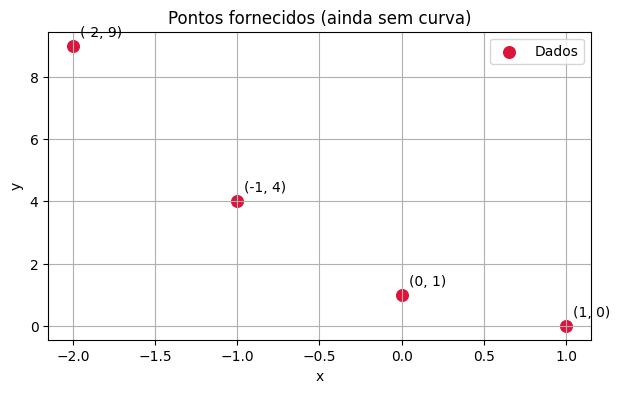

In [9]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=70, label="Dados")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi:g}, {yi:g})", (xi, yi), xytext=(5, 7), textcoords="offset points")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Pontos fornecidos (ainda sem curva)")
plt.grid(True); plt.legend(); plt.show()

**Descrevam a tendência dos pontos.** A curva precisa ser reta? Há mais de uma curva que poderia passar pelos pontos?

**Resposta do teste:** `A curva não precisa ser reta, há de ser um exponencial decrescente ou algo nessa direção. Apesar disso, há mais de uma curva que poderia passar pelos pontos, mesmo que essa curva não indique nenhuma tendência, como uma curva senoidal irregular.`

## 4. Construindo o polinômio com uma ferramenta

Usaremos `numpy.polynomial.Polynomial.fit` para obter o polinômio de grau até $m-1$. O método faz o cálculo numericamente e depois convertemos para a forma usual em potências de $x$.

A expressão impressa pode conter coeficientes muito pequenos, como $10^{-14}$, que representam zero dentro da precisão numérica. Não confundam esses resíduos de arredondamento com termos relevantes.

In [2]:
polinomio = np.polynomial.Polynomial.fit(x, y, deg=len(x)-1).convert()
print("Polinômio na forma usual:")
print(polinomio)
print("\nCoeficientes em ordem crescente (termo constante primeiro):")
print(polinomio.coef)

Polinômio na forma usual:
1.0 - 2.0·x + 1.0·x² + (7.43830132e-16)·x³

Coeficientes em ordem crescente (termo constante primeiro):
[ 1.00000000e+00 -2.00000000e+00  1.00000000e+00  7.43830132e-16]


### Interpretando a expressão

Na forma usual, um polinômio cúbico é escrito como $P(x)=a_0+a_1x+a_2x^2+a_3x^3$. O vetor de coeficientes retornado pelo NumPy segue essa ordem: constante, $x$, $x^2$, $x^3$.

**Registrem a expressão obtida e identifiquem seu grau.** Se algum coeficiente for praticamente zero, indiquem isso.

**Resposta:** `P(x) = 1,0 − 2,0x + 1,0x² + (7,44·10⁻¹⁶)x³. O coeficiente de x³ é praticamente zero (resíduo de arredondamento numérico), então o polinômio é, na prática, de grau 2: P(x) = x² − 2x + 1 = (x − 1)². Os quatro pontos já pertenciam a uma parábola, por isso o grau ficou menor que o máximo possível (3).`

In [3]:
# Conferência automática: comparar P(x_i) com cada y_i
valores_nos_nos = polinomio(x)
for xi, yi, pi in zip(x, y, valores_nos_nos):
    print(f"x={xi:5.1f} | dado={yi:10.6f} | P(x)={pi:10.6f} | diferença={abs(yi-pi):.2e}")

x= -2.0 | dado=  9.000000 | P(x)=  9.000000 | diferença=5.33e-15
x= -1.0 | dado=  4.000000 | P(x)=  4.000000 | diferença=1.78e-15
x=  0.0 | dado=  1.000000 | P(x)=  1.000000 | diferença=6.66e-16
x=  1.0 | dado=  0.000000 | P(x)=  0.000000 | diferença=2.44e-15


**Perguntas de interpretação**

1. As diferenças são zero ou muito pequenas?
2. O que essa conferência mostra sobre a curva nos nós?
3. O que ela **não** mostra sobre valores entre os nós ou fora do intervalo?

**Respostas:** `As diferenças são muito pequenas, a ponto de serem um equivalente prático a zero. Essa conferência mostra que a curva nos nós é decrescente e simultâneamente os valores obtidos convergem com a curva real. Essa conferência não mostra a diferença entre a extraopolação e a interpolação, já que o que teríamos é apenas a interpolação dentro dos pontos dados.`

## 5. Visualizar não é o mesmo que validar

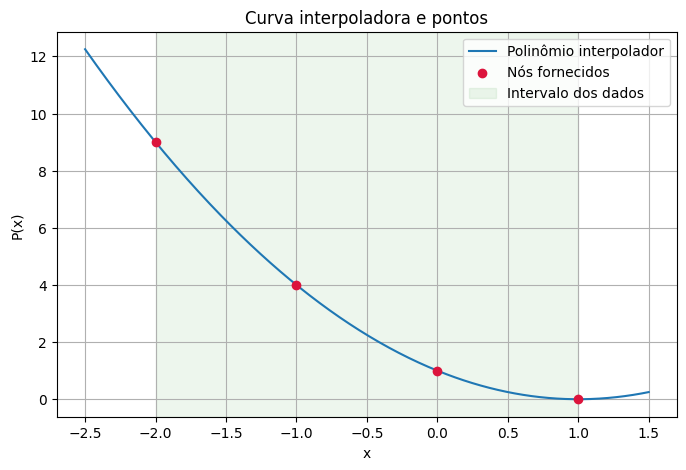

In [4]:
xx = np.linspace(x.min()-0.5, x.max()+0.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, polinomio(xx), label="Polinômio interpolador")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós fornecidos")
plt.axvspan(x.min(), x.max(), color="green", alpha=0.07, label="Intervalo dos dados")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("Curva interpoladora e pontos")
plt.grid(True); plt.legend(); plt.show()

O gráfico ajuda a perceber a forma da curva, mas uma figura pode esconder diferenças pequenas ou induzir a confiar demais em uma região sem dados. A faixa sombreada é o intervalo de interpolação; fora dela estamos extrapolando.

**Descrevam:** a curva passa pelos pontos? O comportamento fora do intervalo parece sustentado pelos dados?
**Resposta:** `A curva passa pelos pontos fixados. Mas como esperado, o corportamento fora do intervalo não necessariamente é sustentado ou parece sustentado pelos dados. Essa curva satisfaz a ideia de que os valores voltariam a crescer com o avanço de X, indicando corpotamento quadrático ou senoidal, mas não exponencial decrescente, que também poderia ser o caso. `

## 6. Calcular valores intermediários

Escolham valores que não aparecem na tabela. O resultado de $P(x)$ é uma estimativa interpolada quando $x$ está entre o menor e o maior nó.

In [13]:
consultas = np.array([-3, 3, -1.27 , 0.67 , 0.13])
for q in consultas:
    tipo = "interpolação" if x.min() <= q <= x.max() else "extrapolação"
    print(f"P({q:4.1f}) = {polinomio(q): .6f}  ({tipo})")

P(-3.0) =  16.000000  (extrapolação)
P( 3.0) =  4.000000  (extrapolação)
P(-1.3) =  5.152900  (interpolação)
P( 0.7) =  0.108900  (interpolação)
P( 0.1) =  0.756900  (interpolação)


**Tabela de registro**

| x consultado | P(x) | Tipo |
|---|---|---|
| −3 | 16,000000 | extrapolação |
| 3 | 4,000000 | extrapolação |
| −1,27 | 5,152900 | interpolação |
| 0,67 | 0,108900 | interpolação |
| 0,13 | 0,756900 | interpolação |

Obs.: o `print` arredonda o x para uma casa decimal (por isso aparece −1.3, 0.7 e 0.1), mas o cálculo foi feito com os valores exatos −1,27, 0,67 e 0,13.

### Atividade: comparar ferramentas

Pesquisem pelo menos **duas** ferramentas além deste código (por exemplo GeoGebra, WolframAlpha, SageMath ou calculadora online). Insiram os mesmos pontos e comparem a expressão e os valores em $x=-1{,}5$ e $x=0{,}5$.

| Ferramenta e link | Como inseriram os dados? | Expressão/resultado | O que foi fácil ou difícil? |
|---|---|---|---|
| 1. **GeoGebra** (Calculadora Gráfica / Classic) – https://www.geogebra.org/classic | Na barra de entrada: `f(x) = Polynomial({(-2,9), (-1,4), (0,1), (1,0)})`, depois `f(-1.5)` e `f(0.5)` | f(x) = x² − 2x + 1; f(−1,5) = 6,25; f(0,5) = 0,25 | Fácil: um único comando e o gráfico aparece junto com os pontos. Difícil: saber que `Polynomial(<lista de pontos>)` faz interpolação, enquanto `FitPoly` faz regressão; usar ponto em vez de vírgula decimal. |
| 2. **WolframAlpha** – https://www.wolframalpha.com | Em linguagem natural: `interpolating polynomial {{-2,9},{-1,4},{0,1},{1,0}}`; depois `x^2 - 2x + 1 at x = -1.5` e `at x = 0.5` | Devolve o polinômio na forma aninhada de Newton/Horner (ex.: 9 + (x+2)(−5 + (x+1))), que expandida dá x² − 2x + 1; valores 6,25 e 0,25 | Fácil: não precisa de sintaxe de programação. Difícil: o resultado não vem na forma expandida, foi preciso expandir/conferir; alguns passos detalhados são só na versão paga. |

Se os resultados diferirem, verifiquem se a ferramenta calculou interpolação polinomial, regressão, spline ou arredondou coeficientes. São operações diferentes.

**Resposta:** `As duas ferramentas concordaram com o código: P(x) = x² − 2x + 1, P(−1,5) = 6,25 e P(0,5) = 0,25 (no NumPy, 6,249999… e 0,250000…). As únicas diferenças foram de apresentação: o NumPy mostra o resíduo de 10⁻¹⁶ no termo x³, que as ferramentas simbólicas não mostram, e o WolframAlpha usa a forma de Newton em vez da forma em potências de x. Como as três fizeram interpolação polinomial exata (e não regressão nem spline), o resultado é o mesmo, o que confirma a unicidade do polinômio interpolador.`

## 7. Segundo conjunto: dados de medição

Agora considere uma sequência simplificada de medições. O valor de $x$ pode representar tempo, e $y$ uma grandeza observada.

1.2 + 1.11666667·x - 0.45·x² + 0.13333333·x³
Estimativa em x=1.5: 2.312500


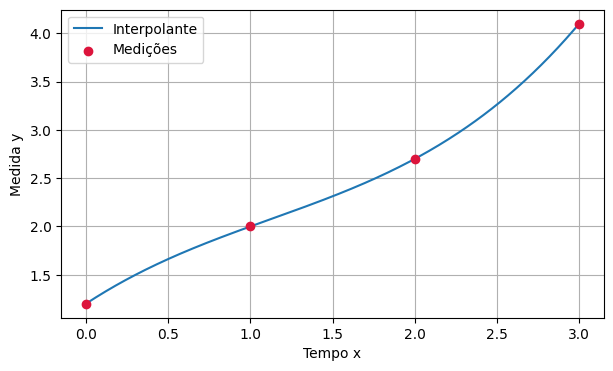

In [6]:
xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 2.7, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, deg=len(xB)-1).convert()
print(pB)
print(f"Estimativa em x=1.5: {pB(1.5):.6f}")
xb_plot = np.linspace(xB.min(), xB.max(), 300)
plt.figure(figsize=(7,4)); plt.plot(xb_plot,pB(xb_plot),label="Interpolante")
plt.scatter(xB,yB,color="crimson",label="Medições",zorder=3)
plt.xlabel("Tempo x"); plt.ylabel("Medida y"); plt.grid(True); plt.legend(); plt.show()

**Discussão:** $x=1{,}5$ está entre nós? Qual a estimativa?
**Resposta:** `X=1,5 está entre dois nós, com estimativa entre 2 e 2,5. Mais precisamente, P(1,5) = 2,312500; como 1,5 está entre os nós x=1 (y=2,0) e x=2 (y=2,7), trata-se de interpolação.`


## 8. Experimento: alterar uma medição

Ajustem somente o valor medido em $x=2$ e observem o efeito na curva. Abaixo usamos uma alteração de $+0{,}5$; vocês podem testar outra.

Estimativa original em x=1.5: 2.312499999999999
Estimativa alterada em x=1.5: 3.437499999999999


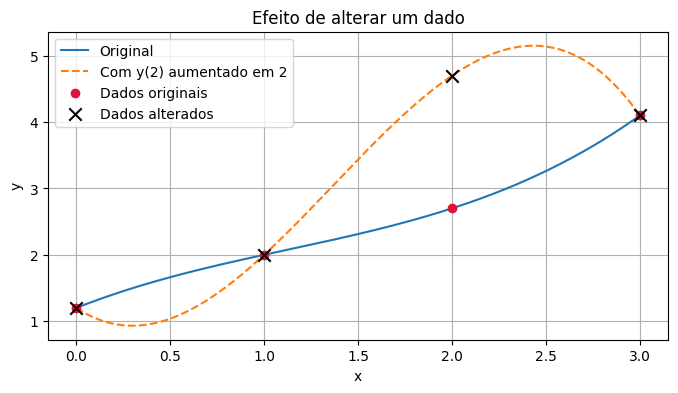

In [15]:
yB_alterado = yB.copy()
yB_alterado[2] += 2.0
pB_alterado = np.polynomial.Polynomial.fit(xB, yB_alterado, deg=len(xB)-1).convert()
print("Estimativa original em x=1.5:", pB(1.5))
print("Estimativa alterada em x=1.5:", pB_alterado(1.5))
plt.figure(figsize=(8,4))
plt.plot(xb_plot,pB(xb_plot),label="Original")
plt.plot(xb_plot,pB_alterado(xb_plot),"--",label="Com y(2) aumentado em 2")
plt.scatter(xB,yB,color="crimson",zorder=3,label="Dados originais")
plt.scatter(xB,yB_alterado,marker="x",s=80,color="black",zorder=4,label="Dados alterados")
plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Efeito de alterar um dado"); plt.show()

**Registrem:** qual ponto foi alterado? O que aconteceu ao valor em $x=1{,}5$? A curva mudou apenas perto do ponto alterado? Por que pequenas incertezas de medição podem ser importantes?
**Resposta:** `O ponto alterado foi o Y quando X=2, X=1,5  mudou em estimativa para o valor de Y, ficando agora entre 3 e 4 (passou de 2,3125 para 3,4375, uma variação de 1,125). A curva não mudou apenas perto do ponto alterado: o polinômio é global, então todos os coeficientes mudaram (de 1,2 + 1,117x − 0,45x² + 0,133x³ para 1,2 − 1,883x + 3,55x² − 0,867x³) e a curva inteira se deslocou, permanecendo fixa apenas nos outros três nós. Por isso pequenas incertezas de medição são importantes: o erro em um único dado se propaga para todas as estimativas do intervalo, e não só para a vizinhança do ponto. `

## 9. Quando o grau alto pode ser um problema?

Com muitos pontos, o polinômio interpolador pode oscilar entre nós, especialmente quando os pontos estão igualmente espaçados. Essa oscilação é um fenômeno conhecido como **fenômeno de Runge** em certos exemplos. Mais pontos e ajuste exato não significam sempre uma curva mais adequada.

A atividade seguinte é uma demonstração visual: comparem uma função suave com polinômios que passam por quantidades crescentes de pontos igualmente espaçados.

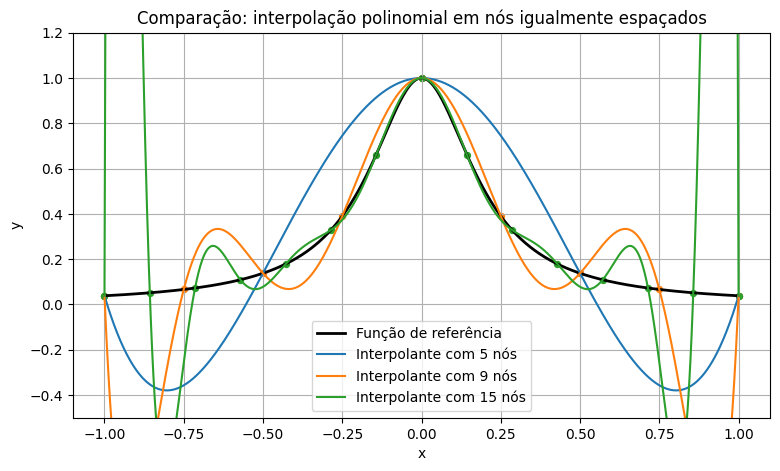

In [8]:
def f(t):
    return 1/(1+25*t**2)

t_plot = np.linspace(-1,1,1000)
plt.figure(figsize=(9,5))
plt.plot(t_plot,f(t_plot),color="black",linewidth=2,label="Função de referência")
for n in [5, 9, 15]:
    tn=np.linspace(-1,1,n)
    pn=np.polynomial.Polynomial.fit(tn,f(tn),deg=n-1).convert()
    plt.plot(t_plot,pn(t_plot),label=f"Interpolante com {n} nós")
    plt.scatter(tn,f(tn),s=18)
plt.ylim(-0.5,1.2); plt.grid(True); plt.legend(); plt.title("Comparação: interpolação polinomial em nós igualmente espaçados")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

**Observação guiada:**

- Todas as curvas interpoladoras passam pelos pontos utilizados?
- O que ocorre perto das extremidades quando aumenta o número de nós?
- Para muitos dados, que alternativas vocês investigariam (por exemplo, interpolação por partes/splines)?

O objetivo é observar, não memorizar uma regra universal: o comportamento depende dos dados, dos nós e do método.
**Resposta:** `Todas as curvas passam por pontos utilizados, variando em quais pontos de acordo com a quantidade de nós selecionada. Perto das extremidades o corportamento das funções interpoladas ou extrapoladas é completamente irregular e não diz nada sobre a função real. Investiariamos um modelo de regressão linear!`

## 10. Interpolação versus regressão

Na interpolação, a curva passa pelos pontos fornecidos. Na **regressão**, escolhemos um modelo que procura representar a tendência geral, sem exigir que passe por cada observação. A regressão pode ser mais apropriada quando há ruído de medição.

| Aspecto | Interpolação | Regressão |
|---|---|---|
| Passa por todos os dados? | Sim (no caso polinomial exato) | Em geral, não |
| Uso comum | Estimar entre dados conhecidos | Representar tendência com dados ruidosos |
| Risco | Oscilação ou extrapolação ruim | Modelo inadequado ou resíduos grandes |

**Expliquem com suas palavras por que a curva interpoladora do conjunto B não prova que as medições são exatas ou sem ruído.**

**Resposta:** `A curva interpoladora do conjunto B passa pelos quatro pontos por construção: com 4 nós distintos sempre existe um único polinômio de grau ≤ 3 que os reproduz, sejam os valores exatos ou contaminados por ruído. Ou seja, o "ajuste perfeito" é uma propriedade do método, e não uma evidência sobre a qualidade dos dados. Se as medições tiverem erro, o polinômio simplesmente incorpora esse erro na curva, como vimos na parte 8, em que alterar y(2) mudou a curva inteira e ela continuou passando por todos os pontos. Na interpolação os resíduos são sempre zero, então eles não informam nada sobre o ruído; para avaliá-lo seria preciso repetir medições ou usar regressão e analisar os resíduos.`

## 11. Síntese e entrega

Escrevam uma síntese de 6–10 linhas, incluindo:
1. o que significa interpolar e a diferença para extrapolar;
2. quais ferramentas foram testadas e se concordaram;
3. o que mudou quando um dado foi alterado;
4. uma limitação observada na interpolação polinomial;
5. em que situação prática usariam o método e que cautela teriam.

**Síntese do grupo:** `Interpolar é estimar valores dentro do intervalo coberto pelos nós usando o polinômio que passa exatamente por eles; extrapolar é usar esse mesmo polinômio fora do intervalo, onde não há dados que sustentem a curva (por exemplo, P(−3) = 16 e P(3) = 4 não têm nenhuma medição que os confirme). Testamos o NumPy, o GeoGebra (comando Polynomial) e o WolframAlpha (interpolating polynomial), e os três concordaram em P(x) = x² − 2x + 1, com P(−1,5) = 6,25 e P(0,5) = 0,25; as diferenças foram só de apresentação (resíduo de 10⁻¹⁶ no NumPy e forma de Newton no WolframAlpha). Ao aumentar y(2) em 2,0 no conjunto B, a estimativa em x = 1,5 passou de 2,3125 para 3,4375 e a curva inteira mudou, porque o polinômio é global. Uma limitação observada foi o fenômeno de Runge: com 15 nós igualmente espaçados, o interpolante oscila fortemente perto das extremidades, ficando longe da função de referência. Usaríamos o método, por exemplo, para estimar a temperatura de um ambiente ou o valor de um sinal fisiológico (como um ECG) entre duas amostras de um sensor, com a cautela de usar poucos nós próximos ao ponto de interesse, não extrapolar e preferir splines ou regressão quando houver muitos dados ou ruído de medição.`


### Checklist
- [x] Expliquei o papel dos nós e do polinômio interpolador.
- [x] Conferi numericamente que o polinômio reproduz os dados.
- [x] Calculei e classifiquei valores consultados como interpolação/extrapolação.
- [x] Comparei duas ferramentas com os mesmos dados.
- [x] Fiz o experimento de alteração de dado e registrei observações.
- [x] Analisei o exemplo com muitos nós e discuti limitações.

